Training images: (3000, 28, 28, 1)
Testing images: (500, 28, 28, 1)


Model: "sequential_52"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_50 (Sequential)      │ (None, 7, 7, 32)       │         4,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_51 (Sequential)      │ (None, 28, 28, 1)      │         4,769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,569 (37.38 KB)

 Trainable params: 9,569 (37.38 KB)

 Non-trainable params: 0 (0.00 B)


Training Convolutional Model
Epoch 1/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.6261 - val_loss: 0.4385
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.2479 - val_loss: 0.1319
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - loss: 0.1028 - val_loss: 0.0786
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0673 - val_loss: 0.0580
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.0514 - val_loss: 0.0462

Convolutional training completed!
Training time: 8.47 seconds


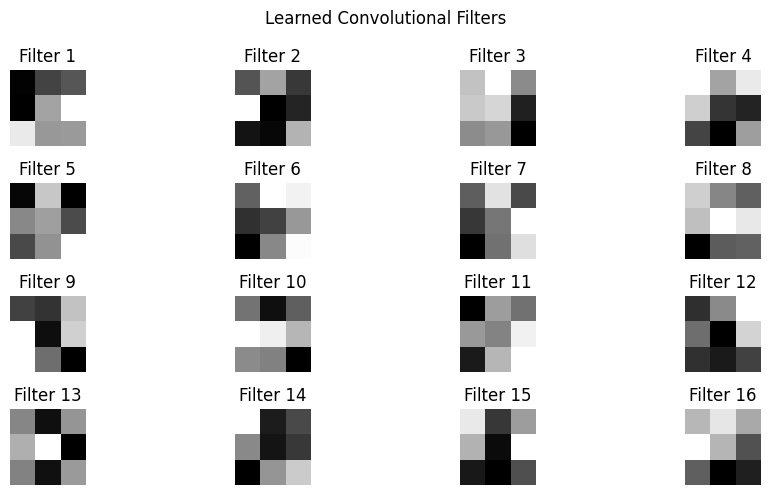

KeyError: "Exception encountered when calling Functional.call().\n\n\x1b[1m138947359286576\x1b[0m\n\nArguments received by Functional.call():\n  • inputs=tf.Tensor(shape=(1, 28, 28, 1), dtype=float32)\n  • training=False\n  • mask=None\n  • kwargs=<class 'inspect._empty'>"

In [32]:
# EXPERIMENT 28: CONVOLUTIONAL BOLTZMANN MACHINE SIMULATION

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from tensorflow.keras.datasets import mnist
from tensorflow.keras import layers, models
from sklearn.neural_network import BernoulliRBM

np.random.seed(42)
tf.random.set_seed(42)

# --------------------------------------------------
# 1. LOAD MNIST DATA
# --------------------------------------------------

(X_train, _), (X_test, _) = mnist.load_data()

X_train = X_train[:3000]
X_test = X_test[:500]

X_train = (X_train / 255.0).astype("float32")
X_test = (X_test / 255.0).astype("float32")

# Binarize images
X_train_bin = (X_train > 0.5).astype("float32")
X_test_bin = (X_test > 0.5).astype("float32")

# Add channel dimension
X_train_cnn = X_train_bin[..., np.newaxis]
X_test_cnn = X_test_bin[..., np.newaxis]

print("Training images:", X_train_cnn.shape)
print("Testing images:", X_test_cnn.shape)

# --------------------------------------------------
# 2. BUILD CONVOLUTIONAL RBM SIMULATION
# --------------------------------------------------

# Encoder
encoder = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")
])

# Decoder
decoder = models.Sequential([
    layers.Input(shape=(7, 7, 32)),
    layers.Conv2DTranspose(
        16, 3, strides=2, padding="same", activation="relu"
    ),
    layers.Conv2DTranspose(
        1, 3, strides=2, padding="same", activation="sigmoid"
    )
])

# Complete reconstruction model
conv_model = models.Sequential([
    encoder,
    decoder
])

conv_model.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

conv_model.summary()

# --------------------------------------------------
# 3. TRAIN CONVOLUTIONAL MODEL
# --------------------------------------------------

print("\nTraining Convolutional Model")

start_time = time.time()

conv_history = conv_model.fit(
    X_train_cnn,
    X_train_cnn,
    epochs=5,
    batch_size=64,
    validation_data=(X_test_cnn, X_test_cnn),
    verbose=1
)

conv_time = time.time() - start_time

print("\nConvolutional training completed!")
print("Training time:", round(conv_time, 2), "seconds")

# --------------------------------------------------
# 4. VISUALIZE FILTERS
# --------------------------------------------------

first_layer = conv_model.layers[0].layers[0]

filters, biases = first_layer.get_weights()

plt.figure(figsize=(10, 5))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    plt.imshow(filters[:, :, 0, i], cmap="gray")
    plt.title("Filter " + str(i + 1))
    plt.axis("off")

plt.suptitle("Learned Convolutional Filters")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 5. VISUALIZE HIDDEN ACTIVATIONS
# --------------------------------------------------

activation_model = tf.keras.Model(
    inputs=conv_model.inputs,
    outputs=conv_model.layers[0].layers[0].output
)

sample_image = X_test_cnn[:1]

activations = activation_model.predict(
    sample_image,
    verbose=0
)

plt.figure(figsize=(10, 5))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    plt.imshow(activations[0, :, :, i], cmap="viridis")
    plt.title("Activation " + str(i + 1))
    plt.axis("off")

plt.suptitle("Hidden Unit Activations")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. GENERATE RECONSTRUCTIONS
# --------------------------------------------------

reconstructed_conv = conv_model.predict(
    X_test_cnn[:10],
    verbose=0
)

plt.figure(figsize=(12, 4))

for i in range(10):

    plt.subplot(2, 10, i + 1)
    plt.imshow(X_test_bin[i], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_conv[i, :, :, 0], cmap="gray")
    plt.title("Recon.")
    plt.axis("off")

plt.suptitle("Original and Convolutional Reconstructions")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. SINGLE-LAYER RBM COMPARISON
# --------------------------------------------------

print("\nTraining Single-Layer RBM")

X_train_flat = X_train_bin.reshape(-1, 784)
X_test_flat = X_test_bin.reshape(-1, 784)

rbm = BernoulliRBM(
    n_components=64,
    learning_rate=0.01,
    n_iter=5,
    batch_size=100,
    random_state=42,
    verbose=True
)

start_time = time.time()

rbm.fit(X_train_flat)

rbm_time = time.time() - start_time

# Reconstruct using RBM
hidden = rbm.transform(X_test_flat[:10])

reconstructed_rbm = np.dot(
    hidden,
    rbm.components_
) + rbm.intercept_visible_

reconstructed_rbm = 1 / (1 + np.exp(-np.clip(
    reconstructed_rbm, -50, 50
)))

# --------------------------------------------------
# 8. DISPLAY RBM RECONSTRUCTIONS
# --------------------------------------------------

plt.figure(figsize=(12, 4))

for i in range(10):

    plt.subplot(2, 10, i + 1)

    plt.imshow(X_test_bin[i], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 10, i + 11)

    plt.imshow(
        reconstructed_rbm[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title("RBM Recon.")
    plt.axis("off")

plt.suptitle("Single-Layer RBM Reconstructions")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. COMPARE RECONSTRUCTION ERROR
# --------------------------------------------------

conv_error = np.mean(
    (X_test_cnn - reconstructed_conv) ** 2
)

rbm_error = np.mean(
    (X_test_flat[:10] - reconstructed_rbm) ** 2
)

print("\nReconstruction Error Comparison")

print("Convolutional Model Error:", round(float(conv_error), 4))
print("Single-Layer RBM Error:", round(float(rbm_error), 4))

# --------------------------------------------------
# 10. COMPARISON GRAPH
# --------------------------------------------------

models_names = ["Convolutional Model", "Single-Layer RBM"]

errors = [conv_error, rbm_error]

plt.figure(figsize=(7, 5))

plt.bar(models_names, errors)

plt.ylabel("Mean Squared Error")
plt.title("Reconstruction Error Comparison")

plt.show()

# --------------------------------------------------
# 11. TRAINING TIME COMPARISON
# --------------------------------------------------

times = [conv_time, rbm_time]

plt.figure(figsize=(7, 5))

plt.bar(models_names, times)

plt.ylabel("Training Time (seconds)")
plt.title("Training Time Comparison")

plt.show()

# --------------------------------------------------
# 12. FINAL RESULTS
# --------------------------------------------------

print("\nFINAL RESULTS")
print("=" * 45)

print("Convolutional Reconstruction Error:",
      round(float(conv_error), 4))

print("Single-Layer RBM Reconstruction Error:",
      round(float(rbm_error), 4))

print("Convolutional Training Time:",
      round(conv_time, 2), "seconds")

print("Single-Layer RBM Training Time:",
      round(rbm_time, 2), "seconds")

print("=" * 45)

print("\nExperiment 28 completed successfully!")